# Homework 9 — Predicting age from CpG methylation: Ridge, LASSO, and Elastic Net

**Module 3 · Hao-Tian Jin · 2026-11-14**

**Summary.** The data set has 1000 simulated samples, 100 CpG features, and a continuous age target. I fix one 80/20 train–test split, standardize the features using training-set moments, and tune each penalty by the same 5-fold cross-validation on the training set. The three models are statistically indistinguishable on the test set: MAE ≈ 6.3 years and $R^2\approx0.83$ for all of them. The penalties differ in the coefficients rather than in accuracy: Ridge keeps all 100 CpGs, LASSO keeps 37, and Elastic Net keeps 43.

| model | penalty strength | nonzero | train MAE | train RMSE | train $R^2$ | test MAE | test RMSE | test $R^2$ |
|---|---|---|---|---|---|---|---|---|
| Ridge | $\alpha=132$ | 100 | 5.41 | 6.71 | 0.875 | 6.34 | 7.83 | 0.832 |
| LASSO | $\alpha=0.279$ | 37 | 5.60 | 6.92 | 0.867 | 6.34 | 7.85 | 0.831 |
| Elastic Net | $\alpha=0.420$, $\rho=0.7$ | 43 | 5.62 | 6.95 | 0.865 | 6.38 | 7.89 | 0.829 |

A coefficient counts as nonzero when $|\hat\beta|>10^{-6}$, matching the solver tolerance. Because $n=1000\gg p=100$ and the signal is spread over many correlated CpGs, sparsity buys a smaller panel, not better prediction. Ridge is the simplest choice when only accuracy matters; Elastic Net is the safer sparse choice when features are correlated.

## Data and protocol

Each row is one sample: `sample_id`, `age_years`, and 100 methylation fractions `sim_CpG_001`–`sim_CpG_100`. There are no missing values. Age spans 18.0–85.0 years (mean 51.5, sd 19.0).

| symbol | meaning |
|---|---|
| $n=1000$, $p=100$ | samples and CpG features |
| $x_{ij}\in[0,1]$ | methylation level of CpG $j$ in sample $i$ |
| $y_i$ | age in years |
| $z_{ij}=(x_{ij}-\hat\mu_j)/\hat\sigma_j$ | standardized feature; $\hat\mu_j,\hat\sigma_j$ from the training set |

The split is 800 training and 200 test samples (`random_state=42`), and the same indices are used for all three models. All tuning happens inside the training set; the test set is touched once, after the models are fixed.

For a prediction $\hat y_i$ the reported numbers are

$$\mathrm{MAE}=\frac1n\sum_i|\hat y_i-y_i|,\qquad
\mathrm{RMSE}=\sqrt{\frac1n\sum_i(\hat y_i-y_i)^2},\qquad
R^2=1-\frac{\sum_i(\hat y_i-y_i)^2}{\sum_i(y_i-\bar y)^2}.$$

Standardization matters because the penalties are not scale invariant: a coefficient on a low-variance CpG would otherwise be penalized differently from the same effect on a high-variance CpG. The intercept is not penalized.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge, Lasso, ElasticNet, LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "legend.frameon": False,
})

DATA_PATH = Path.cwd() / "SIMULATED_CpG_age_1000.csv"
if not DATA_PATH.exists():
    DATA_PATH = Path.cwd() / "module-3-problem" / "SIMULATED_CpG_age_1000.csv"
assert DATA_PATH.exists(), (
    f"Data file not found. Run the notebook from its folder; looked for {DATA_PATH}."
)
ZERO_TOL = 1e-6

data = pd.read_csv(DATA_PATH)
feature_names = [column for column in data.columns if column.startswith("sim_CpG")]
X = data[feature_names].to_numpy()
y = data["age_years"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"samples: {len(data)}, features: {len(feature_names)}")
print(f"training: {len(X_train)}, test: {len(X_test)}")
print(f"age: mean {y.mean():.1f}, sd {y.std():.1f}, range {y.min():.1f}-{y.max():.1f}")
print(f"missing values: {int(data.isna().sum().sum())}")

train_frame = pd.DataFrame(X_train, columns=feature_names)
train_age_correlation = train_frame.corrwith(pd.Series(y_train))
n_strong_correlation = int((train_age_correlation.abs() > 0.5).sum())
print(f"CpGs with |r| > 0.5 with age in training set: {n_strong_correlation}")

samples: 1000, features: 100
training: 800, test: 200
age: mean 51.5, sd 19.0, range 18.0-85.0
missing values: 0
CpGs with |r| > 0.5 with age in training set: 40


## The three estimators

On standardized features all three solve

$$\hat\beta=\arg\min_{\beta_0,\beta}\ \frac{1}{2n}\sum_{i=1}^n\bigl(y_i-\beta_0-z_i^\top\beta\bigr)^2+\alpha\,\Omega(\beta),$$

with

| model | $\Omega(\beta)$ | behavior |
|---|---|---|
| Ridge | $\tfrac12\|\beta\|_2^2$ | shrinks all coefficients smoothly; none becomes exactly zero |
| LASSO | $\|\beta\|_1$ | the corner of the $\ell_1$ ball sets coefficients exactly to zero |
| Elastic Net | $\rho\|\beta\|_1+\tfrac{1-\rho}{2}\|\beta\|_2^2$ | sparse like LASSO, but the $\ell_2$ part lets correlated features share weight |

I select $\alpha$ (and $\rho$ for Elastic Net) by 5-fold cross-validation on the training set, using the same folds for all models and MAE as the criterion, because MAE is the primary metric asked for here. The grids are log-spaced: $10^{-2}$–$10^{4}$ for Ridge and $10^{-4}$–$10$ for LASSO and Elastic Net, with $\rho\in[0.1,1]$.

In [2]:
def make_pipeline(estimator):
    return Pipeline([
        ("scale", StandardScaler()),
        ("model", estimator),
    ])


cv_folds = KFold(n_splits=5, shuffle=True, random_state=0)
scoring = "neg_mean_absolute_error"

ridge_search = GridSearchCV(
    make_pipeline(Ridge()),
    {"model__alpha": np.logspace(-2, 4, 100)},
    cv=cv_folds,
    scoring=scoring,
    n_jobs=-1,
).fit(X_train, y_train)

lasso_search = GridSearchCV(
    make_pipeline(Lasso(max_iter=200_000, tol=1e-6)),
    {"model__alpha": np.logspace(-4, 1, 120)},
    cv=cv_folds,
    scoring=scoring,
    n_jobs=-1,
).fit(X_train, y_train)

elastic_net_search = GridSearchCV(
    make_pipeline(ElasticNet(max_iter=200_000, tol=1e-6)),
    {
        "model__alpha": np.logspace(-4, 1, 70),
        "model__l1_ratio": np.linspace(0.1, 1.0, 10),
    },
    cv=cv_folds,
    scoring=scoring,
    n_jobs=-1,
).fit(X_train, y_train)

models = {
    "Ridge": ridge_search.best_estimator_,
    "LASSO": lasso_search.best_estimator_,
    "Elastic Net": elastic_net_search.best_estimator_,
}

for name, search in [
    ("Ridge", ridge_search),
    ("LASSO", lasso_search),
    ("Elastic Net", elastic_net_search),
]:
    parameters = search.best_params_
    alpha = parameters["model__alpha"]
    if "model__l1_ratio" in parameters:
        l1_ratio = parameters["model__l1_ratio"]
        print(f"{name:12s} CV MAE = {-search.best_score_:.3f}, alpha = {alpha:.4g}, l1_ratio = {l1_ratio:.2f}")
    else:
        print(f"{name:12s} CV MAE = {-search.best_score_:.3f}, alpha = {alpha:.4g}")

Ridge        CV MAE = 5.921, alpha = 132.2
LASSO        CV MAE = 5.892, alpha = 0.2789
Elastic Net  CV MAE = 5.863, alpha = 0.4199, l1_ratio = 0.70


## Cross-validation curves

Before looking at the test set, it is worth checking how sharply the CV error picks each penalty. The stars mark the selected $(\alpha,\mathrm{CV\ MAE})$; for Elastic Net the curve is drawn at the selected $\rho=0.7$. All three curves are flat over an order of magnitude around their minima, so the exact value of the penalty is not critical and the test scores are expected to be close.

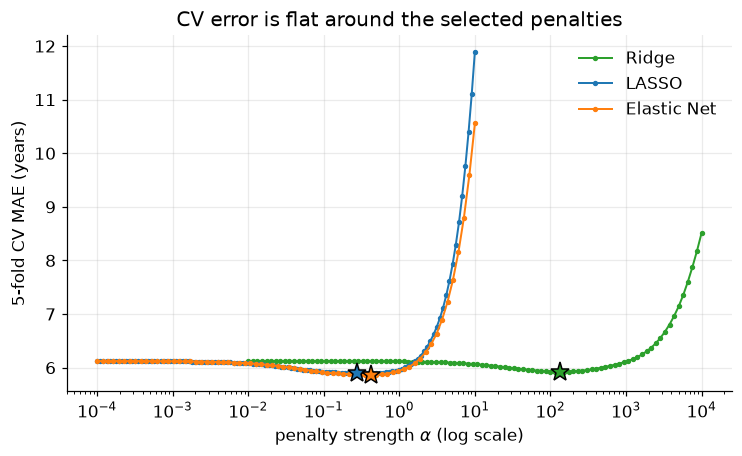

In [3]:
fig, axis = plt.subplots(figsize=(7.8, 4.2))

searches = [
    ("Ridge", ridge_search, "tab:green"),
    ("LASSO", lasso_search, "tab:blue"),
    ("Elastic Net", elastic_net_search, "tab:orange"),
]

for name, search, color in searches:
    parameters = search.cv_results_["params"]
    alphas = np.array([parameter["model__alpha"] for parameter in parameters])
    cv_mae = -search.cv_results_["mean_test_score"]

    if name == "Elastic Net":
        best_l1_ratio = search.best_params_["model__l1_ratio"]
        l1_ratios = np.array([parameter["model__l1_ratio"] for parameter in parameters])
        keep = np.isclose(l1_ratios, best_l1_ratio)
        alphas = alphas[keep]
        cv_mae = cv_mae[keep]

    order = np.argsort(alphas)
    axis.plot(alphas[order], cv_mae[order], "-o", ms=2.5, lw=1.3,
              color=color, label=name)
    axis.plot(search.best_params_["model__alpha"], -search.best_score_,
              "*", ms=13, color=color, markeredgecolor="black", zorder=5)

axis.set_xscale("log")
axis.set_xlabel(r"penalty strength $\alpha$ (log scale)")
axis.set_ylabel("5-fold CV MAE (years)")
axis.set_title("CV error is flat around the selected penalties")
axis.legend()
plt.show()

In [4]:
def metrics_row(name, fitted_model):
    row = {"model": name}
    for split_name, X_part, y_part in [
        ("train", X_train, y_train),
        ("test", X_test, y_test),
    ]:
        prediction = fitted_model.predict(X_part)
        row[f"{split_name} MAE"] = mean_absolute_error(y_part, prediction)
        row[f"{split_name} RMSE"] = np.sqrt(mean_squared_error(y_part, prediction))
        row[f"{split_name} R2"] = r2_score(y_part, prediction)
    estimator = fitted_model.named_steps["model"]
    row["alpha"] = getattr(estimator, "alpha", np.nan)
    row["nonzero"] = int(np.sum(np.abs(estimator.coef_) > ZERO_TOL))
    return row


ols = make_pipeline(LinearRegression()).fit(X_train, y_train)
rows = [metrics_row("OLS (reference)", ols)]
rows += [metrics_row(name, model) for name, model in models.items()]
results = pd.DataFrame(rows).set_index("model")

column_order = [
    "alpha", "nonzero",
    "train MAE", "train RMSE", "train R2",
    "test MAE", "test RMSE", "test R2",
]
results[column_order].round(3)

,alpha,nonzero,train MAE,train RMSE,train R2,test MAE,test RMSE,test R2
model,,,,,,,,
OLS (reference),NaN,100,5.279,6.569,0.880,6.383,7.864,0.830
Ridge,132.194,100,5.414,6.707,0.875,6.343,7.832,0.832
LASSO,0.279,37,5.605,6.921,0.867,6.340,7.846,0.831
Elastic Net,0.420,43,5.622,6.952,0.865,6.376,7.889,0.829


## Results

The table is the only place the test set enters. Two things stand out. First, the three regularized fits are nearly identical on the test set, and none is meaningfully better than OLS, which uses all 100 features without shrinkage. Second, the sparser models pay for their sparsity on the training set (MAE 5.60–5.62 versus 5.41 for Ridge) but recover the difference on the test set. The largest train–test gap is Ridge's 0.93 years; the smallest is LASSO's 0.74 years.

test actual age sd: 19.10 years
Ridge        test prediction sd: 17.43 years
LASSO        test prediction sd: 17.31 years
Elastic Net  test prediction sd: 17.12 years


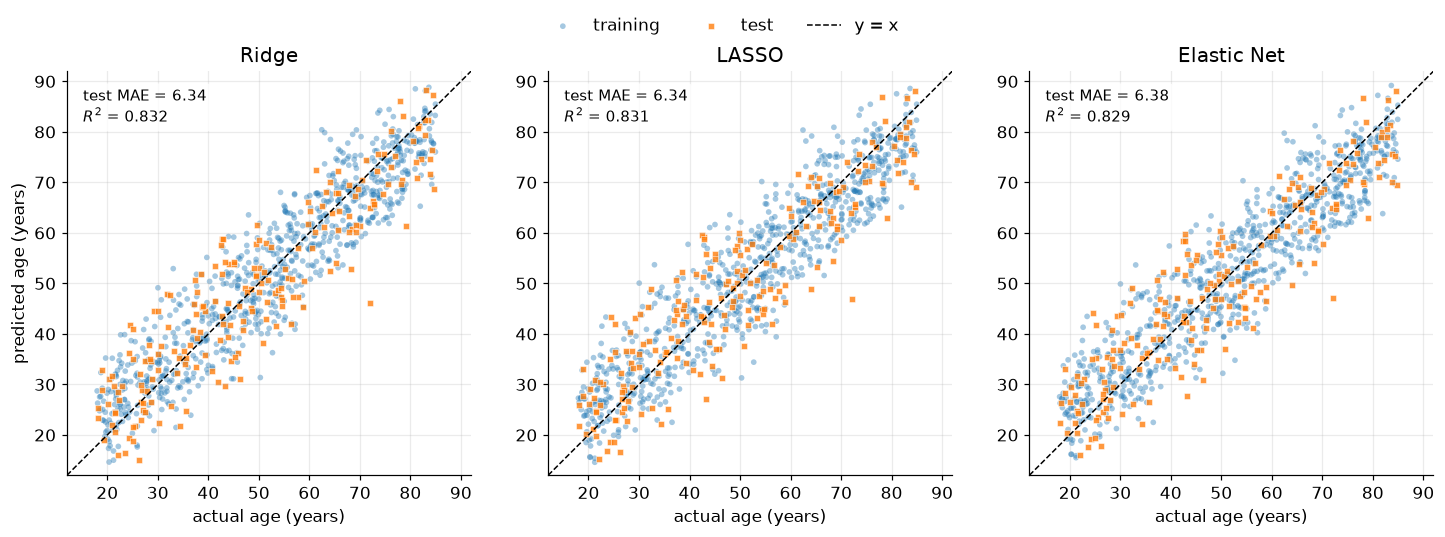

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.6), sharex=True, sharey=True)

for axis, (name, fitted_model) in zip(axes, models.items()):
    train_prediction = fitted_model.predict(X_train)
    test_prediction = fitted_model.predict(X_test)

    axis.scatter(y_train, train_prediction, s=14, alpha=0.40, marker="o",
                 edgecolors="none", color="tab:blue", label="training")
    axis.scatter(y_test, test_prediction, s=20, alpha=0.80, marker="s",
                 edgecolors="white", linewidths=0.4,
                 color="tab:orange", label="test")
    axis.plot([12, 92], [12, 92], "k--", lw=1.0, label="y = x")

    test_mae = mean_absolute_error(y_test, test_prediction)
    test_r2 = r2_score(y_test, test_prediction)
    axis.text(0.04, 0.96, f"test MAE = {test_mae:.2f}\n$R^2$ = {test_r2:.3f}",
              transform=axis.transAxes, va="top", fontsize=10,
              bbox=dict(boxstyle="round,pad=0.25", facecolor="white",
                        edgecolor="none", alpha=0.8))

    axis.set_title(name)
    axis.set_xlabel("actual age (years)")
    axis.set_xlim(12, 92)
    axis.set_ylim(12, 92)
    axis.set_aspect("equal")

for axis in axes:
    axis.tick_params(labelleft=True)

axes[0].set_ylabel("predicted age (years)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.02))
plt.tight_layout(rect=(0, 0, 1, 0.92))

print(f"test actual age sd: {y_test.std():.2f} years")
for name, fitted_model in models.items():
    print(f"{name:12s} test prediction sd: {fitted_model.predict(X_test).std():.2f} years")
plt.show()

## Actual versus predicted age

Each panel compares predicted with actual age; the dashed line is $y=x$. Training points (blue) lie slightly closer to the line than test points (orange), which is the usual optimistic bias of fitting and evaluating on the same data. The cloud is mildly compressed toward the middle: the test-set predictions have standard deviations of 17.1–17.4 years across the three models, against 19.1 years for the actual ages. That regression toward the mean is a property of the linear fit, not of a particular penalty.

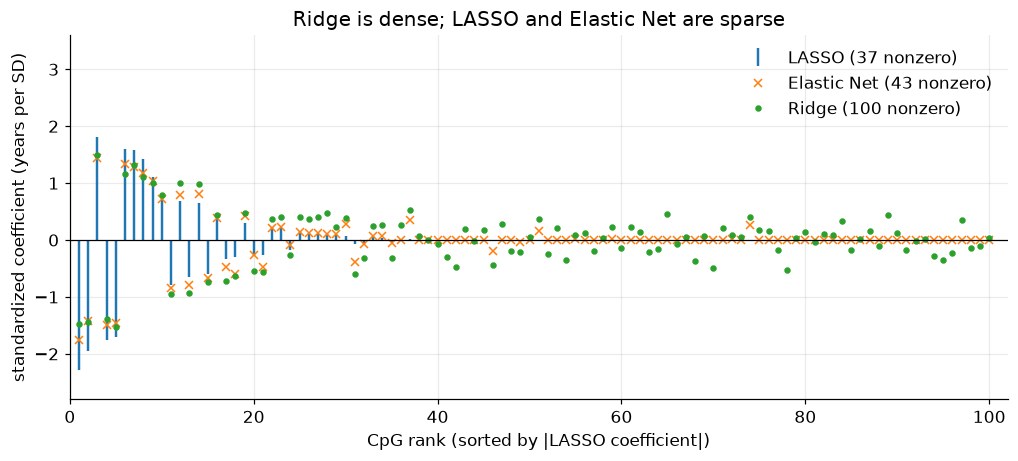

LASSO and Elastic Net share 36 features
LASSO only: 1; Elastic Net only: 7


In [6]:
from matplotlib.lines import Line2D

coefficient_table = pd.DataFrame(
    {name: model.named_steps["model"].coef_ for name, model in models.items()},
    index=feature_names,
)

lasso_coefficients = models["LASSO"].named_steps["model"].coef_
elastic_net_coefficients = models["Elastic Net"].named_steps["model"].coef_
lasso_support = set(np.array(feature_names)[np.abs(lasso_coefficients) > ZERO_TOL])
elastic_net_support = set(np.array(feature_names)[np.abs(elastic_net_coefficients) > ZERO_TOL])

lasso_count = int(np.sum(np.abs(coefficient_table["LASSO"]) > ZERO_TOL))
elastic_net_count = int(np.sum(np.abs(coefficient_table["Elastic Net"]) > ZERO_TOL))
ridge_count = int(np.sum(np.abs(coefficient_table["Ridge"]) > ZERO_TOL))

order = coefficient_table["LASSO"].abs().sort_values(ascending=False).index
coefficient_table = coefficient_table.loc[order]
rank = np.arange(1, len(coefficient_table) + 1)

fig, axis = plt.subplots(figsize=(11, 4.3))
axis.vlines(rank, 0, coefficient_table["LASSO"], color="tab:blue", lw=1.6)
axis.plot(rank, coefficient_table["Elastic Net"], "x", color="tab:orange", ms=5)
axis.plot(rank, coefficient_table["Ridge"], "o", color="tab:green", ms=3.2)
axis.axhline(0, color="black", lw=0.8)
axis.set_xlabel("CpG rank (sorted by |LASSO coefficient|)")
axis.set_xlim(0, 102)
axis.set_ylabel("standardized coefficient (years per SD)")
axis.set_ylim(-2.8, 3.6)
axis.set_title("Ridge is dense; LASSO and Elastic Net are sparse")
legend_handles = [
    Line2D([0], [0], marker="|", color="tab:blue", linestyle="None",
           markersize=12, markeredgewidth=1.6, label=f"LASSO ({lasso_count} nonzero)"),
    Line2D([0], [0], marker="x", color="tab:orange", linestyle="None",
           markersize=5, label=f"Elastic Net ({elastic_net_count} nonzero)"),
    Line2D([0], [0], marker="o", color="tab:green", linestyle="None",
           markersize=3.2, label=f"Ridge ({ridge_count} nonzero)"),
]
axis.legend(handles=legend_handles)
plt.show()

print(f"LASSO and Elastic Net share {len(lasso_support & elastic_net_support)} features")
print(f"LASSO only: {len(lasso_support - elastic_net_support)}; "
      f"Elastic Net only: {len(elastic_net_support - lasso_support)}")

## Where the models actually differ

Sorted by $|\hat\beta_{\rm LASSO}|$, the coefficients tell the whole story. A coefficient counts as nonzero when $|\hat\beta|>10^{-6}$, matching the solver tolerance. Ridge never sets a coefficient to zero: its 100 values are all small and dense. LASSO has exactly 37 nonzero coefficients: after rank 37 the fit is identically zero. Elastic Net keeps 43, and 36 of the 37 LASSO features reappear; the extra 7 are the grouping effect. When several CpGs carry the same latent signal, the $\ell_1$ term is indifferent to which one it keeps, while the $\ell_2$ term encourages the group to share the weight.

In [7]:
rng = np.random.default_rng(123)
test_errors = {
    name: np.abs(model.predict(X_test) - y_test)
    for name, model in models.items()
}
n_test = len(y_test)
n_boot = 4000
boot_mae = {name: np.empty(n_boot) for name in models}

for b in range(n_boot):
    index = rng.integers(0, n_test, n_test)
    for name in models:
        boot_mae[name][b] = test_errors[name][index].mean()

print("Test MAE with bootstrap 95% CI")
for name in models:
    low, high = np.percentile(boot_mae[name], [2.5, 97.5])
    print(f"{name:12s} {test_errors[name].mean():.3f}  [{low:.3f}, {high:.3f}]")

print("\nPairwise difference in test MAE (years)")
for first, second in [
    ("LASSO", "Ridge"),
    ("Elastic Net", "Ridge"),
    ("Elastic Net", "LASSO"),
]:
    difference = boot_mae[first] - boot_mae[second]
    low, high = np.percentile(difference, [2.5, 97.5])
    point = test_errors[first].mean() - test_errors[second].mean()
    print(f"{first} - {second:12s} {point:+.3f}  [{low:+.3f}, {high:+.3f}]")

Test MAE with bootstrap 95% CI
Ridge        6.343  [5.717, 7.011]
LASSO        6.340  [5.713, 7.007]
Elastic Net  6.376  [5.744, 7.057]

Pairwise difference in test MAE (years)
LASSO - Ridge        -0.003  [-0.188, +0.180]
Elastic Net - Ridge        +0.032  [-0.147, +0.211]
Elastic Net - LASSO        +0.035  [-0.041, +0.107]


## Discussion

**Prediction accuracy.** The three models tie: test MAE 6.34 (Ridge), 6.34 (LASSO), 6.38 (Elastic Net); RMSE 7.83/7.85/7.89; $R^2$ 0.832/0.831/0.829. Percentile bootstrap intervals (4000 resamples of the 200 test samples) put each MAE near 5.7–7.0 years, and every pairwise difference interval contains zero (LASSO − Ridge: $-0.003$ years, $[-0.19, 0.18]$). This experiment cannot rank the models.

**Overfitting and the penalty.** Train-to-test MAE rises by 0.93/0.74/0.75 years and $R^2$ falls by 0.043/0.035/0.036. Ridge uses all 100 features but controls variance with its $\ell_2$ penalty. Since $n=1000\gg p=100$, even OLS is not badly overfit (test MAE 6.38), so the penalty is not rescuing an ill-posed problem. It still buys robustness: shrinking $\beta$ reduces sensitivity to training noise and stabilizes estimates when features are correlated, at the cost of a little bias.

**Feature selection.** Ridge is dense, so it cannot say which CpGs matter. LASSO keeps 37 (a 63% reduction); Elastic Net keeps 43 and shares 36 with LASSO. In the training set, 40 CpGs have $|r|>0.5$ with age and many features are correlated, so LASSO's choice inside a correlated group is unstable; the $\ell_2$ part of Elastic Net spreads weight within the group. For a cheaper assay, either sparse model gives a much smaller panel with no measurable loss.

**Relation to real clocks.** The parity above is a property of this simulation, not a general rule. Real epigenetic clocks, notably Horvath's 2013 pan-tissue clock (Genome Biology), use Elastic Net to reduce a 450K array to 353 CpGs and regress on a log-linear transformed age scale. There, CpGs are strongly collinear and age effects are nonlinear, so the grouping effect and the ridge component matter. Horvath's `glmnet` mixing parameter was 0.5; our grid includes that value, but CV chose $\rho=0.7$ here. We predict raw age with a linear model, which is the simplification this simulated data set calls for.

**Caveats.** One 80/20 split gives differences of a few hundredths of a year, far below sampling noise. CV on the training set makes the reported CV scores mildly optimistic, though the test set is untouched. All models are linear, so this isolates the penalty, not the hypothesis class. The data are simulated; nothing here is a biological claim about epigenetic clocks.

## Conclusion

- With one fixed split and one CV protocol, Ridge, LASSO, and Elastic Net all reach test MAE ≈ 6.3 years and $R^2\approx0.83$; the differences are inside the bootstrap noise.
- The penalties change the coefficients, not the accuracy: 100 nonzero coefficients for Ridge, 37 for LASSO, 43 for Elastic Net.
- Overfitting is mild for all three because $n\gg p$. Sparsity is worth it for interpretation or for a smaller assay panel; Elastic Net is the safer sparse choice when CpGs are correlated.